In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

In [54]:
df= pd.read_csv(r"C:\Users\PC\Desktop\Machine Learning\ai_student_impact_dataset (1).csv")

In [55]:
df.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


In [56]:
df.dtypes

Student_ID                      int64
Major_Category                 object
Year_of_Study                  object
Pre_Semester_GPA              float64
Weekly_GenAI_Hours            float64
Primary_Use_Case               object
Prompt_Engineering_Skill       object
Tool_Diversity                  int64
Paid_Subscription                bool
Traditional_Study_Hours       float64
Perceived_AI_Dependency         int64
Institutional_Policy           object
Anxiety_Level_During_Exams      int64
Post_Semester_GPA             float64
Skill_Retention_Score         float64
Burnout_Risk_Level             object
dtype: object

In [57]:
df.isnull().sum()

Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64

In [58]:
df.duplicated().sum()

np.int64(0)

In [59]:
df['Perceived_AI_Dependency'].max()

10

In [60]:
df.drop(['Student_ID','Pre_Semester_GPA','Tool_Diversity','Paid_Subscription','Institutional_Policy','Anxiety_Level_During_Exams','Post_Semester_GPA'],axis = 1, inplace = True)

In [61]:
df.head(10)

,Major_Category,Year_of_Study,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Traditional_Study_Hours,Perceived_AI_Dependency,Skill_Retention_Score,Burnout_Risk_Level
0,Humanities,Senior,23.31,Copywriting/Drafting,Beginner,8.13,5,86.44,High
1,Medical,Junior,1.12,Ideation,Advanced,16.65,3,69.39,Low
2,Business,Freshman,21.26,Summarizing_Reading,Beginner,10.35,5,73.93,Medium
3,Business,Senior,1.82,Copywriting/Drafting,Intermediate,15.23,2,63.58,Medium
4,STEM,Sophomore,9.29,Debugging/Troubleshooting,Advanced,12.55,4,100.00,Medium
5,STEM,Junior,6.50,Debugging/Troubleshooting,Beginner,14.19,4,65.92,High
6,STEM,Freshman,31.41,Summarizing_Reading,Advanced,13.11,8,67.97,Medium
7,Arts,Junior,5.33,Copywriting/Drafting,Intermediate,18.45,2,85.09,Medium
8,Business,Sophomore,2.00,Debugging/Troubleshooting,Beginner,2.87,1,55.71,Medium
9,Business,Sophomore,19.99,Debugging/Troubleshooting,Intermediate,12.49,3,87.18,High


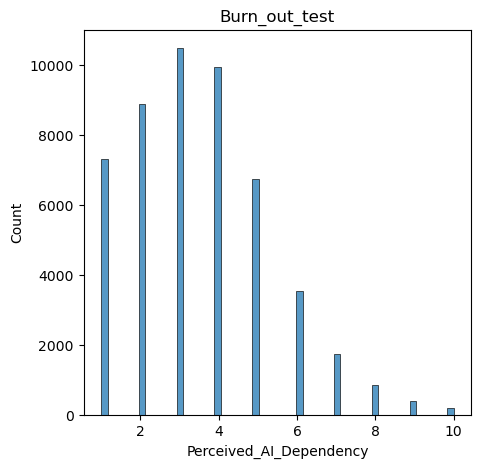

In [62]:
plt.figure(figsize=(5,5))
sns.histplot(df, x = 'Perceived_AI_Dependency')
plt.title('Burn_out_test')
plt.show()

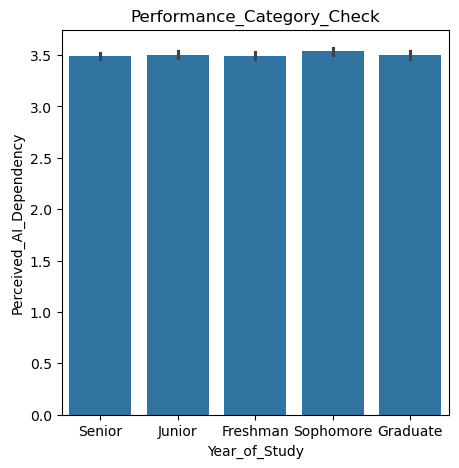

In [63]:
plt.figure(figsize = (5,5))
sns.barplot(df,y = 'Perceived_AI_Dependency', x= 'Year_of_Study')
plt.title( 'Performance_Category_Check')
plt.show()

In [64]:
df['Year_of_Study'].max()

'Sophomore'

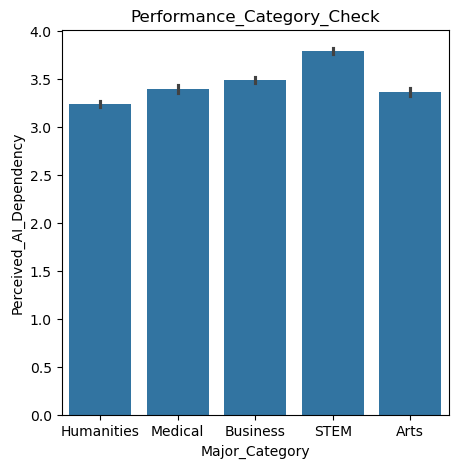

In [65]:
plt.figure(figsize = (5,5))
sns.barplot(df,y = 'Perceived_AI_Dependency', x= 'Major_Category')
plt.title( 'Performance_Category_Check')
plt.show()

In [66]:
df['Major_Category'].max()

'STEM'

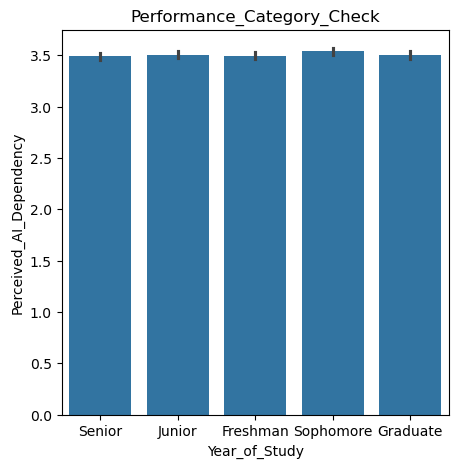

In [67]:
plt.figure(figsize = (5,5))
sns.barplot(df,y = 'Perceived_AI_Dependency', x= 'Year_of_Study')
plt.title( 'Performance_Category_Check')
plt.show()

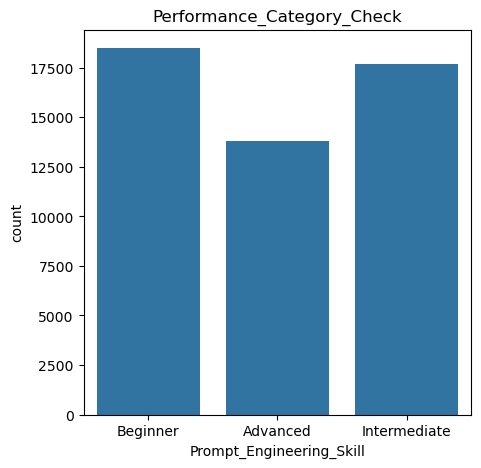

In [68]:
plt.figure(figsize = (5,5))
sns.countplot(df,x = 'Prompt_Engineering_Skill')
plt.title( 'Performance_Category_Check')
plt.show()

In [69]:
df['Prompt_Engineering_Skill'].max()

'Intermediate'

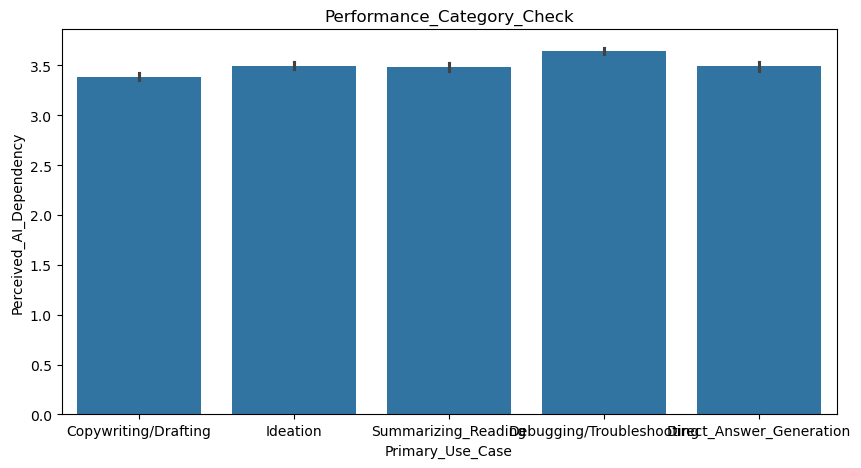

In [70]:
plt.figure(figsize = (10,5))
sns.barplot(df,y = 'Perceived_AI_Dependency', x= 'Primary_Use_Case')
plt.title( 'Performance_Category_Check')
plt.show()

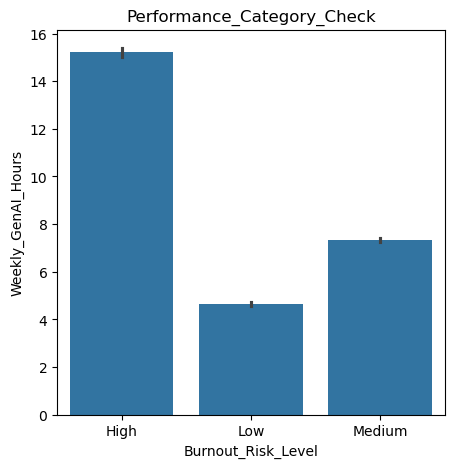

In [71]:
plt.figure(figsize = (5,5))
sns.barplot(df,y = 'Weekly_GenAI_Hours', x= 'Burnout_Risk_Level')
plt.title( 'Performance_Category_Check')
plt.show()

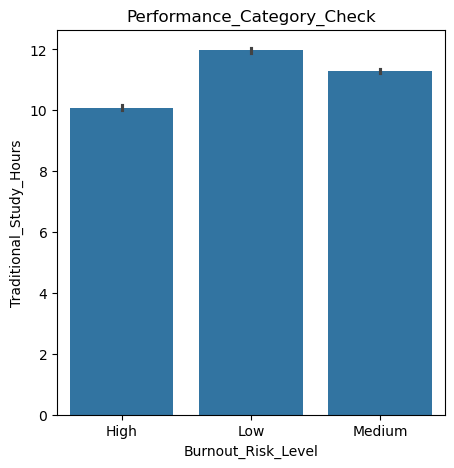

In [72]:
plt.figure(figsize = (5,5))
sns.barplot(df,y = 'Traditional_Study_Hours', x= 'Burnout_Risk_Level')
plt.title( 'Performance_Category_Check')
plt.show()

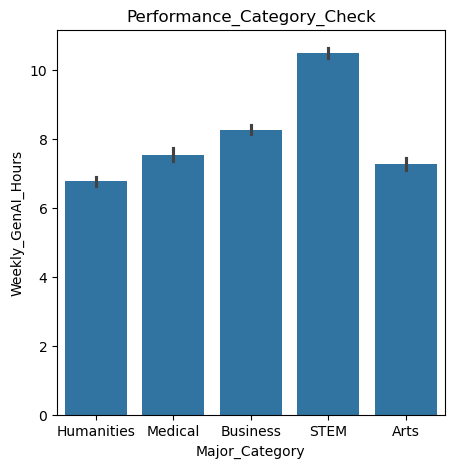

In [73]:
plt.figure(figsize = (5,5))
sns.barplot(df,y = 'Weekly_GenAI_Hours', x= 'Major_Category')
plt.title( 'Performance_Category_Check')
plt.show()

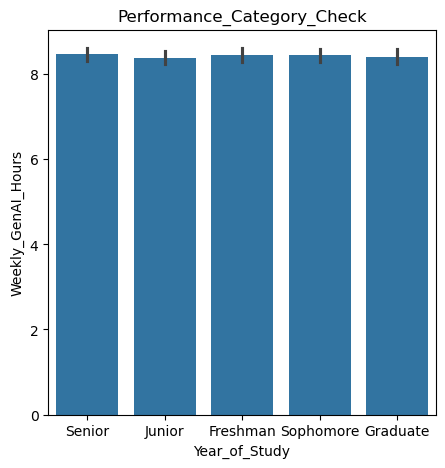

In [74]:
plt.figure(figsize = (5,5))
sns.barplot(df,y = 'Weekly_GenAI_Hours', x= 'Year_of_Study')
plt.title( 'Performance_Category_Check')
plt.show()

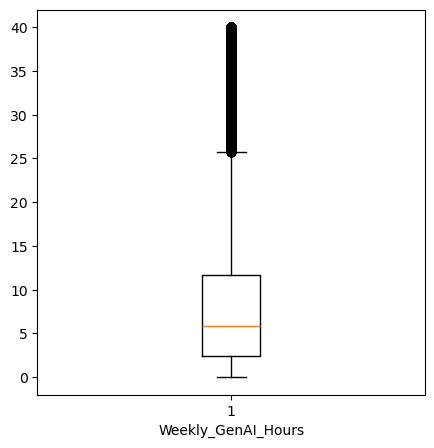

In [75]:
plt.figure(figsize=(5,5))
plt.boxplot(df['Weekly_GenAI_Hours'])
plt.xlabel('Weekly_GenAI_Hours')
plt.show()

In [76]:
column = ['Weekly_GenAI_Hours','Traditional_Study_Hours']

In [77]:
dfclean = df.copy()

In [78]:
for col in column:
    Q1 = dfclean[col].quantile(0.25)
    Q3 = dfclean[col].quantile(0.75) 
    IQR = Q3 - Q1

In [79]:
lower = Q1 - 1.0 * IQR
upper = Q3 + 1.0 * IQR

In [80]:
dfclean = dfclean[(dfclean[col]>=lower) & (dfclean[col]<=upper)]

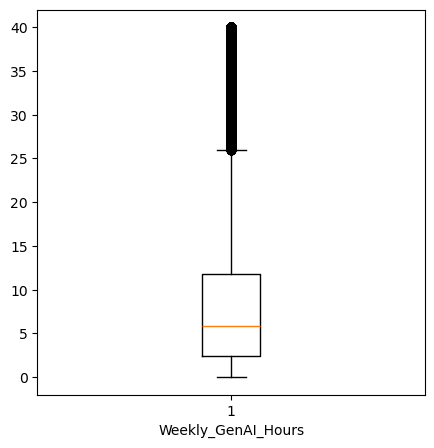

In [81]:
plt.figure(figsize=(5,5))
plt.boxplot(dfclean['Weekly_GenAI_Hours'])
plt.xlabel('Weekly_GenAI_Hours')
plt.show()

In [82]:
label = LabelEncoder()

In [83]:
textcol = df[['Major_Category','Year_of_Study','Primary_Use_Case','Prompt_Engineering_Skill','Burnout_Risk_Level']]

In [84]:
for col in textcol:
    df[col] = label.fit_transform(df[col])

In [85]:
df.head()

,Major_Category,Year_of_Study,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Traditional_Study_Hours,Perceived_AI_Dependency,Skill_Retention_Score,Burnout_Risk_Level
0,2,3,23.31,0,1,8.13,5,86.44,0
1,3,2,1.12,3,0,16.65,3,69.39,1
2,1,0,21.26,4,1,10.35,5,73.93,2
3,1,3,1.82,0,2,15.23,2,63.58,2
4,4,4,9.29,1,0,12.55,4,100.00,2


In [86]:
x = df.drop('Burnout_Risk_Level', axis = 1)
y = df['Burnout_Risk_Level']

In [87]:
x.shape

(50000, 8)

In [88]:
y.shape

(50000,)

In [89]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y,random_state = 42, test_size = 0.2)

In [90]:
dtc = DecisionTreeClassifier()

In [91]:
dtc.fit(xtrain,ytrain)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [92]:
dtcpred = dtc.predict(xtest)

In [93]:
dtcpred[:10]

array([2, 2, 2, 2, 2, 1, 2, 1, 1, 0])

In [94]:
dtc_acc = accuracy_score(dtcpred, ytest)*100

In [95]:
dtc_acc

43.4

In [96]:
logr = LogisticRegression()

In [97]:
logr.fit(xtrain,ytrain)

C:\Users\PC\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [98]:
logrpred = logr.predict(xtest)

In [99]:
logrpred[:20]

array([1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 1, 0, 1, 2, 2, 0, 1, 2, 0])

In [100]:
logr_acc = accuracy_score(logrpred, ytest)*100

In [101]:
logr_acc

50.949999999999996

In [108]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix

In [105]:
print(classification_report(ytest,logrpred))

              precision    recall  f1-score   support

           0       0.67      0.43      0.52      2536
           1       0.50      0.46      0.48      3269
           2       0.47      0.60      0.53      4195

    accuracy                           0.51     10000
   macro avg       0.54      0.49      0.51     10000
weighted avg       0.53      0.51      0.51     10000



In [109]:
cm = confusion_matrix(ytest,logrpred)

In [110]:
cm

array([[1082,  277, 1177],
       [  91, 1491, 1687],
       [ 448, 1225, 2522]])